# Retrieve Colocated EMIT Satellite Data

## Overview

**[AVUELO](https://www.earthdata.nasa.gov/data/projects/avuelo)** was airborne measurements over tropical ecosystems, which is useful for validation of space borne instruments. In this tutorial we will use an instrument on the International Space Station (ISS) and retrieve data colocated to AVUELO's airborne AVIRIS-3 imagery:

- **[EMIT](https://www.earthdata.nasa.gov/data/instruments/emit-imaging-spectrometer)** (Earth Surface Mineral Dust Source Investigation) is an imaging spectrometer with a design similar to AVIRIS-3. Its [L2A surface reflectance](https://doi.org/10.5067/EMIT/EMITL2ARFL.001) covers 381–2493 nm spectral range in 285 bands at ~60 m spatial resolution.

In this tutorial, we find EMIT data that coincide with the AVIRIS-3 flights over **Barro Colorado Island (BCI)**, Panama. We will:

1. find the dates of the AVIRIS-3 flights over the study area
2. search EMIT L2A reflectance within a time window, check cloud cover over the study area with the EMIT masks, and compare EMIT with AVIRIS-3 reflectance

## Requirements

- A NASA [Earthdata Login](https://urs.earthdata.nasa.gov/) account
- See the [prerequisites](../../docs/prerequisites.md) page for setup instructions.

## Import Libraries

In [1]:
import os
import aiohttp
import fsspec
import earthaccess
import h5py
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import rioxarray
import pyproj
import matplotlib.pyplot as plt
from rasterio import features
from rasterio.enums import Resampling
from scipy.ndimage import binary_dilation
from shapely.geometry import box
import warnings
warnings.filterwarnings('ignore')

# ESRI basemap for interactive maps
xyz = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"
attr = "ESRI"

## Authentication
`earthaccess.login()` authenticates with your Earthdata Login credentials. If you have a `.netrc` file or `EARTHDATA_USERNAME` and `EARTHDATA_PASSWORD` environment variables, login completes without a prompt. Searching does not require login, but streaming and downloading data do.

In [85]:
auth = earthaccess.login()

## Study Area and AVIRIS-3 Flight Dates

Our study area is a the Barro Colorado Island BCI 50-ha plot, incidated by `plot_code=p50`. This is the same plot we also used in the Tutorial 2. We first find the dates when AVIRIS-3 flew over the area.

In [3]:
# study area 
plots = gpd.read_file('data/avuelo_forest_plots.geojson')
p50 = plots[plots.plot_code == 'p50']
p50bounds = tuple(p50.to_crs(epsg=4326).total_bounds)
av3 = earthaccess.search_data(short_name='AVUELO_AV3_L2A_Reflectance_2479',
                              bounding_box=p50bounds,
                              granule_name='*RFL_ORT*')


In [4]:
def granule_details(g):
    """Returns granule metadata as a dictionary."""
    umm = g['umm']
    return {
        'granule': umm.get('GranuleUR'),
        'version': umm['CollectionReference']['Version'],
        'scene_cloud_pct': umm.get('CloudCover', {}),
        'start_time': pd.to_datetime(pd.to_datetime(umm['TemporalExtent']['RangeDateTime']['BeginningDateTime'])),
        'url': g.data_links()[0],
        'granule_obj': g
    }
# create a geopandas dataframe from granule details
gdf = gpd.GeoDataFrame([granule_details(g) for g in av3],
                       geometry=gpd.GeoSeries(av3, crs='EPSG:4326'))
# sorting by start time
gdf = gdf.sort_values('start_time').reset_index(drop=True)
gdf['start_date']=gdf['start_time'].dt.date.astype(str)
print(f"AVIRIS-3 scenes over the study area: {len(gdf.index)}")
print("Flight dates:", gdf['start_date'].unique().tolist())

AVIRIS-3 scenes over the study area: 19
Flight dates: ['2025-02-06', '2025-02-10', '2025-02-24', '2025-02-25', '2025-02-26']


In [5]:
m = gdf.explore(column='start_date', tiles=xyz, attr=attr,
                tooltip=['granule', 'start_time'],
                style_kwds={'weight': 1})
# ploting the study area in red
p50.explore(m=m, style_kwds={'color': 'red', 'weight': 3})

## Part 1: EMIT L2A Surface Reflectance

### Search within a time window

We start with a strict window: EMIT overpasses during the AVIRIS-3 campaign, from 6 to 28 February 2025. We search by the dataset short name `EMITL2ARFL`, which returns all versions of the dataset. EMIT data are being reprocessed to version 2 (`002`) and may not be available for the AVUELO coverage. We keep both versions.

In [6]:
def emit_search(roi, temporal):
    # searches EMIT L2A reflectance granules and returns them in a dataframe
    results = earthaccess.search_data(short_name='EMITL2ARFL',
                                bounding_box=roi,
                                temporal=temporal)
    gdf = gpd.GeoDataFrame([granule_details(g) for g in results],
                       geometry=gpd.GeoSeries(results, crs='EPSG:4326'))
    return gdf.sort_values('start_time').reset_index(drop=True)

emit_campaign = emit_search(p50bounds, ('2025-02-06', '2025-02-28'))
emit_campaign[['granule', 'version', 'start_time', 'scene_cloud_pct']]

,granule,version,start_time,scene_cloud_pct
0,EMIT_L2A_RFL_001_20250218T182640_2504912_029,001,2025-02-18 18:26:40+00:00,94


As we see above, only Version 001 is available for the time period. `scene_cloud_pct` is the cloud cover of the whole EMIT scene (~75 km × 75 km). It says little about our much smaller study area, so we check the EMIT cloud masks over the study area itself.

### Orthorectify a subset of an EMIT granule

EMIT L2A files are in the instrument's swath geometry (`downtrack`, `crosstrack`). Each file includes a geometric lookup table (GLT) that gives, for each pixel of a north-up latitude/longitude grid, the swath row and column to use. To get an orthorectified subset of the study area, we only need the part of the GLT inside the study area, and only the swath rows and columns it points to. The function below reads just these pixels from the remote file.

In [7]:
def emit_ortho_subset(f, var, bounds):
    """Returns an orthorectified subset of an EMIT L2A variable within bounds."""
    dt = xr.open_datatree(f[0], engine='h5netcdf')
    gt = [float(v) for v in dt.attrs['geotransform']]
    loc = dt['location']
    # centers of the lat/lon grid cells
    lon = gt[0] + gt[1] * (np.arange(loc.sizes['ortho_x']) + 0.5)
    lat = gt[3] + gt[5] * (np.arange(loc.sizes['ortho_y']) + 0.5)
    xi = np.where((lon >= bounds[0]) & (lon <= bounds[2]))[0]
    yi = np.where((lat >= bounds[1]) & (lat <= bounds[3]))[0]
    if len(xi) == 0 or len(yi) == 0:
        return None, dt
    glt_x = loc['glt_x'][yi[0]:yi[-1] + 1, xi[0]:xi[-1] + 1].values.astype(int)
    glt_y = loc['glt_y'][yi[0]:yi[-1] + 1, xi[0]:xi[-1] + 1].values.astype(int)
    valid = (glt_x > 0) & (glt_y > 0)  # 0 means no data; GLT indices start at 1
    if not valid.any():
        return None, dt
    # read only the swath rows and columns we need
    r0, r1 = glt_y[valid].min() - 1, glt_y[valid].max()
    c0, c1 = glt_x[valid].min() - 1, glt_x[valid].max()
    swath = dt[var][r0:r1, c0:c1, :].values
    out = np.full(glt_x.shape + (swath.shape[-1],), np.nan, dtype='float32')
    out[valid] = swath[glt_y[valid] - 1 - r0, glt_x[valid] - 1 - c0]
    da = xr.DataArray(out, dims=('y', 'x', 'band'),
                      coords={'y': lat[yi], 'x': lon[xi]})
    return da.rio.write_crs('EPSG:4326'), dt

### Cloud cover over the study area

The EMIT L2A mask file (`EMIT_L2A_MASK`) has eight layers. Four of them flag pixels that should not be used for surface analysis:

| Layer | Meaning |
|---|---|
| `Cloud flag` | Cloud |
| `Cirrus flag` | Thin cirrus cloud |
| `Dilated Cloud Flag` | Cloud flag expanded to include cloud edges and nearby shadows |
| `Spacecraft Flag` | View blocked by parts of the ISS |

The mask also has a `Water flag` and an `Aggregate Flag`. The aggregate flag combines all flags, including water, so it would remove Gatun Lake around BCI. Since we want to keep the lake, we combine the four flags above ourselves.

The function below computes the percentage of the study area covered by an EMIT granule, and the percentage of the covered area that is clear.

In [8]:
unusable_flags = ['Cloud flag', 'Cirrus flag', 'Dilated Cloud Flag', 'Spacecraft Flag']

def emit_links(g):
    """Returns the reflectance, uncertainty, and mask file links of an EMIT granule."""
    links = [u for u in g.data_links() if u.endswith('.nc')]
    rfl = [u for u in links if '_RFL_' in os.path.basename(u)][0]
    msk = [u for u in links if '_MASK_' in os.path.basename(u)][0]
    return rfl, msk

def emit_unusable(mask_da, dt):
    """True where any of the unusable flags is set."""
    names = list(dt['sensor_band_parameters']['mask_bands'].values)
    idx = [names.index(n) for n in unusable_flags]
    return (mask_da.isel(band=idx) == 1).any('band')

def emit_clear_fraction(g, bounds):
    """Percent bounds covered by the granule and percent clear."""
    _, msk_url = emit_links(g)
    mask_da, dt = emit_ortho_subset(earthaccess.open([msk_url]), 'mask', bounds)
    if mask_da is None:
        return 0.0, 0.0
    covered = mask_da.isel(band=0).notnull()
    clear = covered & ~emit_unusable(mask_da, dt)
    return (round(100 * float(covered.mean()), 1),
            round(100 * float(clear.sum() / max(covered.sum(), 1)), 1))

emit_campaign[['coverage_pct', 'clear_pct']] = [emit_clear_fraction(g, p50bounds)
                                                for g in emit_campaign.granule_obj]
emit_campaign[['granule', 'start_time', 'scene_cloud_pct', 'coverage_pct', 'clear_pct']]

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

,granule,start_time,scene_cloud_pct,coverage_pct,clear_pct
0,EMIT_L2A_RFL_001_20250218T182640_2504912_029,2025-02-18 18:26:40+00:00,94,84.3,0.0


The only EMIT overpass during the campaign, on 18 February 2025, covers 84% of the study area, but less than 0% of the covered area is clear. The rest is flagged as cloud or cloud edge. As is common in the humid tropics, no usable EMIT data coincide with the AVIRIS-3 flights.

This can also be seen in the image browse image below, where major chunk of middle of the scene is missing.

In [9]:
emit_campaign.iloc[0].granule_obj

Collection: {'ShortName': 'EMITL2ARFL', 'Version': '001'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Longitude': -79.38123321533203, 'Latitude': 9.756207466125488}, {'Longitude': -79.97623443603516, 'Latitude': 9.320881843566895}, {'Longitude': -79.49112701416016, 'Latitude': 8.657849311828613}, {'Longitude': -78.89612579345703, 'Latitude': 9.093174934387207}, {'Longitude': -79.38123321533203, 'Latitude': 9.756207466125488}]}}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2025-02-18T18:26:40Z', 'EndingDateTime': '2025-02-18T18:26:51Z'}}
Size(MB): 3577.785192489624
Data: ['https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/EMITL2ARFL.001/EMIT_L2A_RFL_001_20250218T182640_2504912_029/EMIT_L2A_RFL_001_20250218T182640_2504912_029.nc', 'https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/EMITL2ARFL.001/EMIT_L2A_RFL_001_20250218T182640_2504912_029/EMIT_L2A_RFLUNCERT_001_20250218T182640_2504912_029.nc', 'https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/EMITL2ARFL.001/EMIT_L2A_RFL_001_20250218T182640_2504912_029/EMIT_L2A_MASK_001_20250218T182640_2504912_029.nc']

### Widen the time window

AVUELO flew in the dry season, when clouds are least frequent. We search the same season (January–April) in the years before and after the campaign. The `temporal` argument takes one range, so we search each year separately. This step might take several minutes to complete.

In [10]:
emit_dry = pd.concat([emit_search(p50bounds, (f'{y}-01-01', f'{y}-04-30')) for y in [2024, 2025, 2026]],
                     ignore_index=True)
emit_dry[['coverage_pct', 'clear_pct']] = [emit_clear_fraction(g, p50bounds) for g in emit_dry.granule_obj]
emit_dry[['granule', 'version', 'start_time', 'scene_cloud_pct', 'coverage_pct', 'clear_pct']]

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

...

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

,granule,version,start_time,scene_cloud_pct,coverage_pct,clear_pct
0,EMIT_L2A_RFL_001_20240126T173251_2402612_002,001,2024-01-26 17:32:51+00:00,89,100.0,100.0
1,EMIT_L2A_RFL_001_20240224T170614_2405511_028,001,2024-02-24 17:06:14+00:00,98,100.0,15.0
2,EMIT_L2A_RFL_001_20240228T153149_2405910_007,001,2024-02-28 15:31:49+00:00,99,100.0,0.0
3,EMIT_L2A_RFL_001_20240303T135639_2406309_003,001,2024-03-03 13:56:39+00:00,99,100.0,0.0
4,EMIT_L2A_RFL_001_20250128T154905_2502811_004,001,2025-01-28 15:49:05+00:00,100,100.0,0.0
5,EMIT_L2A_RFL_001_20250218T182640_2504912_029,001,2025-02-18 18:26:40+00:00,94,84.3,0.0
6,EMIT_L2A_RFL_001_20260223T160048_2605411_018,001,2026-02-23 16:00:48+00:00,89,100.0,0.0
7,EMIT_L2A_RFL_001_20260321T184000_2608012_006,001,2026-03-21 18:40:00+00:00,71,100.0,0.0
8,EMIT_L2A_RFL_001_20260325T170901_2608411_007,001,2026-03-25 17:09:01+00:00,22,100.0,100.0
9,EMIT_L2A_RFL_001_20260420T175419_2611011_049,001,2026-04-20 17:54:19+00:00,55,100.0,100.0


Ten EMIT granules from the January–April dry seasons of 2024–2026 cover the study area. Note how poorly the scene-level cloud cover predicts the conditions over the study area: the scene of 26 January 2024 is 89% cloudy as a whole, but the study area is completely clear, while the scene of 18 February 2026 is only 94% cloudy, but 84.3% of the study area is flagged. Currently, only version `001` granules were available for these dates.

We select the granules with the largest clear area over the study area.

In [11]:
emit_dry['clear_area_pct'] = emit_dry.coverage_pct * emit_dry.clear_pct / 100
best = emit_dry[emit_dry['clear_area_pct'] == emit_dry['clear_area_pct'].max()]
best[['granule', 'version', 'clear_area_pct']]

,granule,version,clear_area_pct
0,EMIT_L2A_RFL_001_20240126T173251_2402612_002,001,100.0
8,EMIT_L2A_RFL_001_20260325T170901_2608411_007,001,100.0
9,EMIT_L2A_RFL_001_20260420T175419_2611011_049,001,100.0


### Open the EMIT reflectance

We read the orthorectified reflectance and the mask of the study area from each of the three selected granules. We set the unusable pixels and the bad bands (`good_wavelengths` = 0, the deep water vapor absorption bands) to `NaN`. Each granule has its own latitude/longitude grid, so we keep the three subsets separate, in a dictionary indexed by the acquisition date.

Note that granules processed with different versions of the EMIT software can have slightly different band centers and bad bands. For example, the granule of 2024 has 244 good bands, and the granules of 2026 have 255. We therefore keep the wavelengths and good bands of each granule.

In [12]:
emit = {}
for row in best.itertuples():
    rfl_url, msk_url = emit_links(row.granule_obj)
    rfl, dt = emit_ortho_subset(earthaccess.open([rfl_url]), 'reflectance', p50bounds)
    msk, mdt = emit_ortho_subset(earthaccess.open([msk_url]), 'mask', p50bounds)
    bp = dt['sensor_band_parameters']
    rfl = rfl.assign_coords(wavelength=('band', bp['wavelengths'].values))
    good_bands = bp['good_wavelengths'].values == 1
    rfl = rfl.where(~emit_unusable(msk, mdt))
    rfl = rfl.where(xr.DataArray(good_bands, dims='band'))
    date = f"{row.start_time:%Y-%m-%d}"
    emit[date] = {'rfl': rfl, 'good_bands': good_bands}
    print(f"{date}: {dict(rfl.sizes)}, good bands: {good_bands.sum()}, "
          f"software build: {dt.attrs.get('software_build_version')}")

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

...

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

2026-04-20: {'y': 9, 'x': 17, 'band': 285}, good bands: 255, software build: 010635


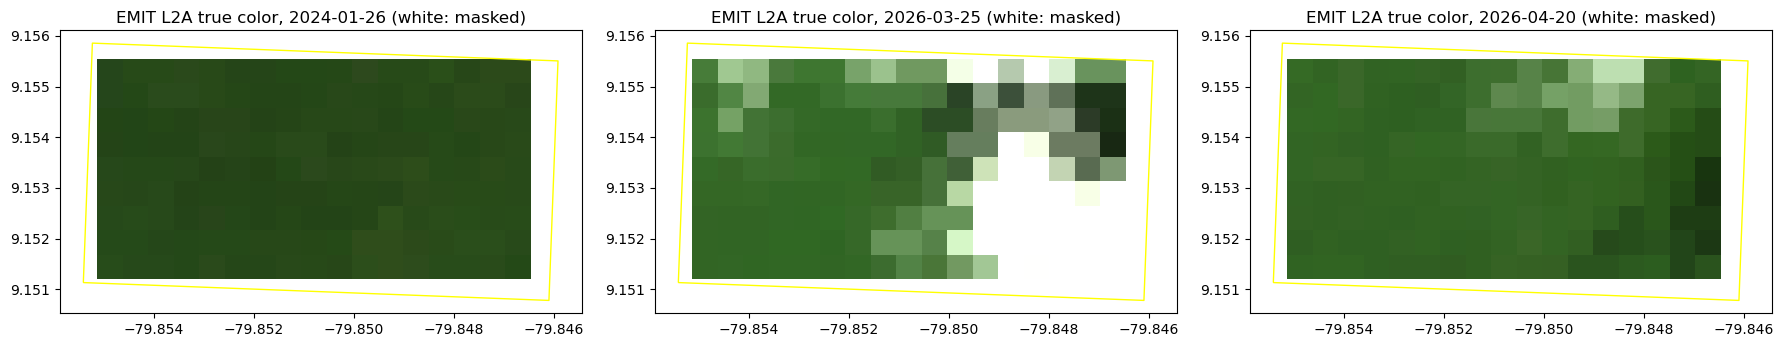

In [13]:
def rgb(da, scale=0.15):
    # true-color RGB array from a DataArray with a wavelength coordinate
    bands = [np.abs(da.wavelength.values - w).argmin() for w in [650, 560, 470]]
    out = np.clip(da.isel(band=bands).values / scale, 0, 1)
    out[np.isnan(out).any(axis=-1)] = 1
    return out

fig, axes = plt.subplots(1, len(emit), figsize=(6 * len(emit), 5))
for ax, (date, d) in zip(np.atleast_1d(axes), emit.items()):
    da = d['rfl']
    ext = [float(da.x.min()), float(da.x.max()), float(da.y.min()), float(da.y.max())]
    ax.imshow(rgb(da), extent=ext)
    p50.to_crs('EPSG:4326').boundary.plot(ax=ax, color='yellow', lw=1)
    ax.set_title(f"EMIT L2A true color, {date} (white: masked)")
plt.tight_layout()
plt.show()

The granule of 2026-03-25 is also brighter in the visible and shortwave infrared, and its true-color image shows bright pixels over part of the plot: a cloud or haze that was not flagged by the EMIT mask. 

### Compare EMIT with AVIRIS-3

We compare the three EMIT acquisitions with the AVIRIS-3 scene `AV320250206t193402_006`, acquired on 6 February 2025 at ~3.4 m resolution, which covers the whole BCI 50-ha plot. In case of clouds, we first mask AVIRIS-3 cloud pixels: forest and water are dark in the blue, with a reflectance of ~0.02 at 470 nm, while clouds are bright. We mask pixels brighter than 0.08 at 470 nm, and all pixels within 30 m of them, to also remove cloud edges and most cloud shadows.

To compare the two sensors at the same scale and wavelengths, for each EMIT granule we select the AVIRIS-3 bands nearest to its good bands. We also leave out the bands in the two deep water vapor absorption regions (1340–1450 nm and 1790–1960 nm) for all granules, because some processing versions of EMIT do not flag all of them as bad. We then average the AVIRIS-3 pixels within each ~60 m EMIT pixel with `rioxarray`'s `reproject_match()` and average resampling. We keep only the EMIT pixels that are fully covered by valid AVIRIS-3 pixels and clear in EMIT.

In [72]:
scene_id = 'AV320250206t193402_006'
scene_granules = earthaccess.search_data(short_name='AVUELO_AV3_L2A_Reflectance_2479',
                                         granule_name=f'*{scene_id}*RFL_ORT*')
av3_f = earthaccess.open([scene_granules[0]])
av3_date = f"{pd.to_datetime(scene_granules[0]['umm']['TemporalExtent']['RangeDateTime']['BeginningDateTime']):%Y-%m-%d}"

dt = xr.open_datatree(av3_f[0], engine='h5netcdf')
av3_crs = pyproj.CRS.from_wkt(dt['transverse_mercator'].attrs['crs_wkt'])
av3_all = dt['reflectance']['reflectance'].rename({'easting': 'x',
                                                   'northing': 'y'}).rio.write_crs(av3_crs)
# renaming wavelength diminesions to bands as it is in EMIT
av3_all = av3_all.to_dataset(name="reflectance").rename_dims({"wavelength": "band"})["reflectance"]

# window: the 50-ha plot with a 100 m buffer, all bands
p50_utm = p50.to_crs(av3_crs)
x0, y0, x1, y1 = p50_utm.total_bounds + np.array([-100, -100, 100, 100])
av3_win = av3_all.sel(x=slice(x0, x1), y=slice(y1, y0)).load()

# mask clouds (bright at 470 nm) and pixels within 30 m of them
pixel_size = abs(float(av3_all.x[1] - av3_all.x[0]))
blue = av3_win.sel(wavelength=470, method='nearest').values
cloud = binary_dilation(blue > 0.08, iterations=max(1, int(30 / pixel_size)))
av3_win = av3_win.where(xr.DataArray(~cloud, dims=('y', 'x'))).rio.write_crs(av3_crs).rio.write_nodata(np.nan)
print(f"AVIRIS-3 {av3_date}, pixel size {pixel_size:.1f} m, window: {dict(av3_win.sizes)}, "
      f"cloud and cloud-edge pixels: {100 * cloud.mean():.1f}%")

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

AVIRIS-3 2025-02-06, pixel size 3.4 m, window: {'band': 284, 'y': 164, 'x': 306}, cloud and cloud-edge pixels: 0.0%


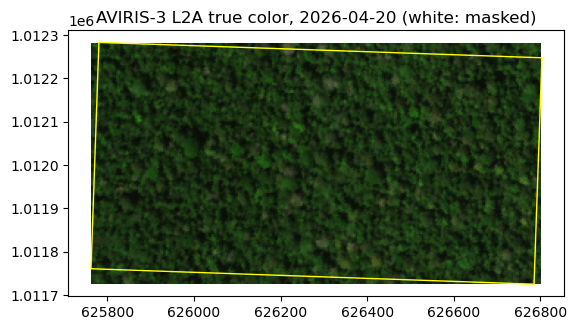

In [73]:
fig, ax = plt.subplots()
ext = [float(av3_win.x.min()), float(av3_win.x.max()),
       float(av3_win.y.min()), float(av3_win.y.max())]
ax.imshow(np.moveaxis(rgb(av3_win), 0, -1), extent=ext)
p50_utm.boundary.plot(ax=ax, color='yellow', lw=1)
ax.set_title(f"AVIRIS-3 L2A true color, {date} (white: masked)")
plt.show()

In [78]:
# fraction of each pixel covered by valid AVIRIS-3 pixels
valid = av3_win.isel(band=0).notnull().astype('float32').rio.write_crs(av3_crs).rio.write_nodata(-1)

pairs = {}
for date, d in emit.items():
    # EMIT good bands of this granule, outside the water vapor absorption regions, as a (band, y, x) array
    wl_all = d['rfl'].wavelength.values
    absorption = ((wl_all > 1340) & (wl_all < 1450)) | ((wl_all > 1790) & (wl_all < 1960))
    bands_used = np.where(d['good_bands'] & ~absorption)[0]
    emit_good = d['rfl'].isel(band=bands_used).transpose('band', 'y', 'x').rio.write_crs('EPSG:4326')
    emit_good = emit_good.rio.set_spatial_dims(x_dim='x', y_dim='y')
    wl = emit_good.wavelength.values
    # AVIRIS-3 bands nearest to the EMIT good bands, averaged within each EMIT pixel
    av3_avg = (av3_win.sel(wavelength=wl, method='nearest')
               .rio.reproject_match(emit_good.isel(band=0), resampling=Resampling.average))
    coverage = valid.rio.reproject_match(emit_good.isel(band=0), resampling=Resampling.average)
    use = (coverage.values > 0.99) & np.isfinite(emit_good.values).all(axis=0)
    # spectra of the pixels used, as (band, pixel) arrays
    pairs[date] = {'wl': wl, 'emit': emit_good.values[:, use], 'av3': av3_avg.values[:, use]}
    print(f"EMIT {date}: {use.sum()} pixels fully covered by AVIRIS-3 and clear in EMIT")

EMIT 2024-01-26: 153 pixels fully covered by AVIRIS-3 and clear in EMIT
EMIT 2026-03-25: 153 pixels fully covered by AVIRIS-3 and clear in EMIT
EMIT 2026-04-20: 153 pixels fully covered by AVIRIS-3 and clear in EMIT


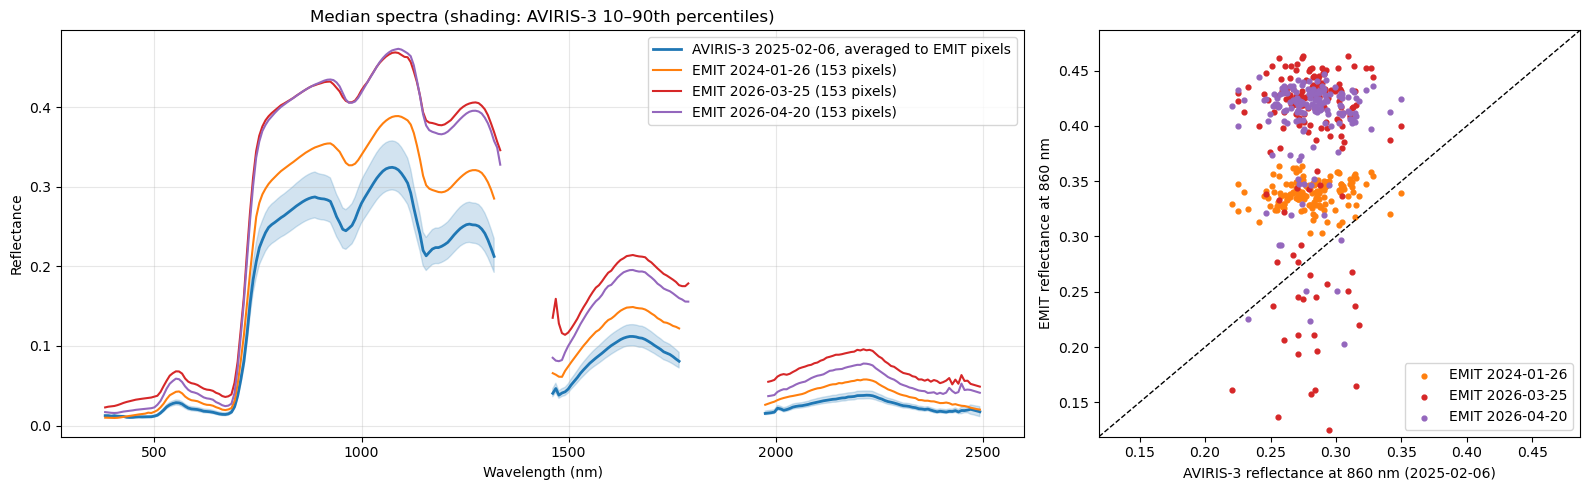

In [79]:
def gaps(wl, values, max_step=20):
    # inserts NaN where wavelengths jump, so lines break at the bad bands
    out = values.astype(float).copy()
    out[1:][np.diff(wl) > max_step] = np.nan
    return out

emit_colors = ['tab:orange', 'tab:red', 'tab:purple']
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [2, 1]})
ax = axes[0]
# AVIRIS-3, averaged to the EMIT pixels and bands of the first granule
ref = next(iter(pairs.values()))
ax.fill_between(ref['wl'], gaps(ref['wl'], np.percentile(ref['av3'], 10, axis=1)),
                np.percentile(ref['av3'], 90, axis=1), color='tab:blue', alpha=0.2)
ax.plot(ref['wl'], gaps(ref['wl'], np.median(ref['av3'], axis=1)), color='tab:blue', lw=2,
        label=f'AVIRIS-3 {av3_date}, averaged to EMIT pixels')
for (date, p), color in zip(pairs.items(), emit_colors):
    ax.plot(p['wl'], gaps(p['wl'], np.median(p['emit'], axis=1)), color=color,
            label=f"EMIT {date} ({p['emit'].shape[1]} pixels)")
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Reflectance')
ax.set_title('Median spectra (shading: AVIRIS-3 10–90th percentiles)')
ax.legend()
ax.grid(alpha=0.3)

ax = axes[1]
values = []
for (date, p), color in zip(pairs.items(), emit_colors):
    nir = np.abs(p['wl'] - 860).argmin()
    ax.scatter(p['av3'][nir], p['emit'][nir], s=12, color=color, label=f'EMIT {date}')
    values += [p['av3'][nir], p['emit'][nir]]
values = np.concatenate(values)
lim = [values.min() * 0.95, values.max() * 1.05]
ax.plot(lim, lim, 'k--', lw=1)
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel(f'AVIRIS-3 reflectance at 860 nm ({av3_date})')
ax.set_ylabel('EMIT reflectance at 860 nm')
ax.legend()
plt.tight_layout()
plt.show()

The three EMIT acquisitions and AVIRIS-3 have the same spectral shape. Their brightness, however, differs. EMIT from 2024-01-26 is the closest to AVIRIS-3, but brighter.  EMIT scenes from 2026-03-25 and 2026-04-20 are even brighter than the EMIT 2024 granule. Its scatter plot also has a group of low NIR values (0.15–0.27), likely cloud shadows.

The cause of the brighter 2026 spectra cannot be explained from these data alone. Possible causes include haze or thin clouds, seasonal changes in the canopy.  AVIRIS-3 also differs from all three EMIT granules in date (by one year or more), viewing geometry, and calibration, which is provisional for the AVUELO data.

Pixel by pixel, the EMIT values are not well correlated with the AVIRIS-3 averages: the forest canopy is fairly uniform at the 60 m scale, and small geolocation offsets mean that the pixels of the two sensors may not cover exactly the same trees.